In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
TEXT_COL = "text"
LABEL_COL = "label"

SAMPLE_SIZE = 200
RANDOM_SEED = 20261026
NUM_REPETITIONS = 10

from pathlib import Path
from datetime import datetime
import json
import pickle

# Resolve paths whether VS Code starts in the workspace root or EnvData.
DATA_DIR = Path.cwd()
if (DATA_DIR / "EnvData" / "environmental_claims_dataset_original.csv").exists():
    DATA_DIR = DATA_DIR / "EnvData"
if not (DATA_DIR / "environmental_claims_dataset_original.csv").exists():
    raise FileNotFoundError("Open this notebook in the GR workspace or EnvData directory.")
ROOT = DATA_DIR.parent
OUTPUT_DIR = DATA_DIR / "results" / ("uncertainty10_gpu_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Results directory:", OUTPUT_DIR.resolve())
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable: select the RTX 5080 Python environment before running.")
print("GPU:", torch.cuda.get_device_name(0))
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
# Avoid TF32 approximation when comparing CPU/GPU cosine scores.
torch.backends.cuda.matmul.allow_tf32 = False


Results directory: /home/amyliu/Desktop/GR/EnvData/results/uncertainty10_gpu_20261025_163632
GPU: NVIDIA GeForce RTX 5080


In [3]:
csv = DATA_DIR / "environmental_claims_dataset_original.csv"
df = pd.read_csv(csv)
print(df.head())
print(df.columns)
print(df.shape)

                                                text  label
0  The project will make a significant contributi...      1
1  So in -- first of all, the segments, we are --...      0
2  Building a smarter and stronger energy grid th...      0
3  Generally, first of all our Transmission depar...      0
4  But for the most part, our challenge is showin...      0
Index(['text', 'label'], dtype='str')
(2647, 2)


In [4]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"[?|!|\'|\"|#]", "", text)
    text = re.sub(r"[.|,|)|(|\\|/]", " ", text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def load_and_clean_dataset(csv_file):
    df = pd.read_csv(csv_file)
    df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().copy()

    df["clean_sentence"] = df[TEXT_COL].apply(clean_text)
    df["length"] = df["clean_sentence"].apply(len)

    print(df.head())
    print(df[LABEL_COL].value_counts())
    print(df.shape)

    return df

In [5]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [6]:
TEXT_COL = "text"
LABEL_COL = "label"
df = load_and_clean_dataset(csv)

                                                text  label  \
0  The project will make a significant contributi...      1   
1  So in -- first of all, the segments, we are --...      0   
2  Building a smarter and stronger energy grid th...      0   
3  Generally, first of all our Transmission depar...      0   
4  But for the most part, our challenge is showin...      0   

                                      clean_sentence  length  
0  The project will make a significant contributi...     141  
1  So in -- first of all the segments we are -- w...      91  
2  Building a smarter and stronger energy grid th...     146  
3  Generally first of all our Transmission depart...     157  
4  But for the most part our challenge is showing...     127  
label
0    1982
1     665
Name: count, dtype: int64
(2647, 4)


In [7]:
df = add_length_quantile_groups(df)
print(df.head())
print(df.columns)
print(df.shape)

quantiles
Q1      32
Q2      26
Q3      28
Q4      20
Q5      38
        ..
Q96     25
Q97     29
Q98     25
Q99     25
Q100    27
Name: count, Length: 100, dtype: int64
                                                text  label  \
0  The project will make a significant contributi...      1   
1  So in -- first of all, the segments, we are --...      0   
2  Building a smarter and stronger energy grid th...      0   
3  Generally, first of all our Transmission depar...      0   
4  But for the most part, our challenge is showin...      0   

                                      clean_sentence  length quantiles  
0  The project will make a significant contributi...     141       Q47  
1  So in -- first of all the segments we are -- w...      91       Q15  
2  Building a smarter and stronger energy grid th...     146       Q50  
3  Generally first of all our Transmission depart...     157       Q58  
4  But for the most part our challenge is showing...     127       Q37  
Index(['text'

In [8]:
def sample_from_length_groups(df, sample_size=200, num_quantiles=100, random_seed=42):
    n_samples = sample_size // num_quantiles

    sampled_df = (
        df.groupby("quantiles", group_keys=False)
        .apply(lambda x: x.sample(n=min(n_samples, len(x)), random_state=random_seed))
        .reset_index(drop=True)
    )

    print("Actual Sample Size:", len(sampled_df))
    print("Minimum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).min())
    print("Average Token Count:", sampled_df["clean_sentence"].str.split().apply(len).mean())
    print("Maximum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).max())

    return sampled_df

In [9]:
sampled_df = sample_from_length_groups(
    df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED
)

Actual Sample Size: 200
Minimum Token Count: 11
Average Token Count: 24.455
Maximum Token Count: 39


In [10]:
sampled_df.head()

,text,label,clean_sentence,length
0,"And to your point, yes, the labor costs have c...",0,And to your point yes the labor costs have com...,52
1,"And when you look at Mexico, Mexico is a big p...",0,And when you look at Mexico Mexico is a big place,49
2,Indeed it is the public sector which has incre...,0,Indeed it is the public sector which has incre...,59
3,"I mean, so you might get a $15 million deal on...",0,I mean so you might get a $15 million deal on ...,58
4,"Well, over a 2-year period, we I think there's...",0,Well over a 2-year period we I think theres go...,65


In [11]:
df["labels"] = (
    df["label"]
    .apply(
        lambda value: [
            str(int(value))
        ]
    )
)

print(
    df[
        [
            "label",
            "labels",
        ]
    ].head()
)

   label labels
0      1    [1]
1      0    [0]
2      0    [0]
3      0    [0]
4      0    [0]


In [12]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [13]:
def asymmetry_eta(x, bandwidth=None):
    """Original leave-one-out eta estimator, evaluated in float64 on CUDA.

    Row chunks limit GPU memory; strict empirical CDF handles ties exactly.
    """
    with torch.inference_mode():
        x = torch.as_tensor(np.asarray(x, dtype=float), device="cuda", dtype=torch.float64)
        x = x[~torch.isnan(x)]
        n = x.numel()
        if n < 3:
            return np.nan
        s = x.std(correction=1)
        q = torch.quantile(x, torch.tensor([0.25, 0.75], device=x.device, dtype=x.dtype))
        iqr = q[1] - q[0]
        sigma = torch.minimum(s, iqr / 1.349) if iqr.item() > 0 else s
        if torch.isclose(sigma, torch.zeros_like(sigma), rtol=1e-5, atol=1e-8).item():
            sigma = s if s.item() > 0 else x.new_tensor(1.0)
        h = x.new_tensor(bandwidth) if bandwidth is not None else 0.9 * sigma * n ** (-1 / 5)
        if h.item() <= 0:
            h = 1.06 * (s if s.item() > 0 else x.new_tensor(1.0)) * n ** (-1 / 5)
        f_hat = torch.empty_like(x)
        normalizer = (2 * np.pi) ** -0.5
        for start in range(0, n, 128):
            end = min(start + 128, n)
            kernel = (x.unsqueeze(0) - x[start:end].unsqueeze(1)) / h
            kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
            kernel[torch.arange(end-start, device=x.device), torch.arange(start,end,device=x.device)] = 0
            f_hat[start:end] = kernel.sum(dim=1) / ((n - 1) * h)
        F_hat = torch.searchsorted(torch.sort(x).values, x, right=False).to(x.dtype) / (n - 1)
        if f_hat.std(correction=1).item() == 0 or F_hat.std(correction=1).item() == 0:
            return np.nan
        return (-torch.corrcoef(torch.stack((f_hat, F_hat)))[0, 1]).item()


In [14]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):
    # Preserve NumPy bin edges and boundary conventions; count and reduce on GPU.
    edges = np.histogram_bin_edges(dist1, bins=bins, range=value_range)
    edges = torch.as_tensor(edges, device="cuda", dtype=torch.float64)
    def histogram(values):
        values = torch.as_tensor(np.asarray(values), device="cuda", dtype=torch.float64)
        valid = (values >= edges[0]) & (values <= edges[-1])
        indices = torch.bucketize(values[valid], edges, right=True) - 1
        indices.clamp_(max=edges.numel()-2)
        counts = torch.bincount(indices, minlength=edges.numel()-1).to(torch.float64)
        return counts / counts.sum()
    p, q = histogram(dist1), histogram(dist2)
    return (0.5 * ((p-q).square() / (p+q+eps)).sum()).item()


In [15]:
def create_cosine_similarity_matrix(embeddings):
    with torch.inference_mode():
        normalized = F.normalize(embeddings.detach().to("cuda", dtype=torch.float32), p=2, dim=1)
        return (normalized @ normalized.T).cpu().numpy()


In [16]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [17]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [18]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [19]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = torch.as_tensor(same_scores, device="cuda", dtype=torch.float64).mean().item()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = torch.as_tensor(sampled_diff_scores, device="cuda", dtype=torch.float64).mean().item()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)
        if (b + 1) % 100 == 0:
            print(f"Bootstrap {b + 1}/{n_bootstrap}", flush=True)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [20]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [21]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=10,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    output_dir=None,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        (output_dir / "run_config.json").write_text(json.dumps({
            "statistics_device": "cuda", "dataset": "EnvData",
            "master_seed": master_seed, "repetition_seeds": repetition_seeds.tolist(),
            "num_repetitions": num_repetitions, "models": models,
            "sample_size_requested": sample_size, "num_quantiles": num_quantiles,
            "batch_size": batch_size, "max_token": max_token,
            "n_bootstrap": n_bootstrap, "bins": bins, "value_range": value_range,
            "eta_bandwidth": eta_bandwidth, "text_col": text_col, "label_col": label_col,
        }, indent=2))

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                )
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        if output_dir is not None:
            sampled_df.to_csv(output_dir / f"sample_{repetition + 1:02d}.csv", index=False)

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary["actual_sample_size"] = len(sampled_df)
            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

            if output_dir is not None:
                model_file = model_name.replace("/", "__")
                with (output_dir / f"rep_{repetition + 1:02d}_{model_file}.pkl").open("wb") as handle:
                    pickle.dump(result, handle, protocol=pickle.HIGHEST_PROTOCOL)
                pd.DataFrame(summary_results).to_csv(output_dir / "summary_per_run.csv", index=False)
                print(f"Saved {len(summary_results)}/{num_repetitions * len(models)} model runs", flush=True)

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [22]:
results = metric_collect(
    grouped_df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=NUM_REPETITIONS,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col="clean_sentence",
    label_col="labels",
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/10
Repetition seed: 2601517389
Actual Sample Size: 200
Minimum Token Count: 11
Average Token Count: 24.52
Maximum Token Count: 39
Actual sample size: 200
Label counts:
labels
0    149
1     51
Name: count, dtype: int64
Number of represented labels: 2

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 12301
Number of label-set pair types: 1
Total unique between-label document pairs: 7599
Same-label target size: 12301
Different-label pair types: 1
Base sample per diff-label pair: 12301
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.6759771936604206
Different mean: 0.6825602489259803
Mean gap: -0.006583055265559697
Same eta: -0.07094576464059377
Different eta: -0.0919874237687402
Different |eta|: 0.0919874237687402
Eta gap: 0.021041659128146435
Chi-square distance: 0.006639931253757338
Chi-square bootstrap std: 0.0006622479547139766
Saved 1/70 model runs

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (202 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 12204
Number of label-set pair types: 1
Total unique between-label document pairs: 7696
Same-label target size: 12204
Different-label pair types: 1
Base sample per diff-label pair: 12204
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.8401711727753501
Different mean: 0.8368510135750825
Mean gap: 0.003320159200267569
Same eta: -0.32511543948924637
Different eta: -0.2319477918334919
Different |eta|: 0.2319477918334919
Eta gap: -0.09316764765575448
Chi-square distance: 0.0054306909428957755
Chi-square bootstrap std: 0.0006490618050774457
Saved 70/70 model runs


,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.675977,-0.070946,0.070946,12301,0.682560,0.000555,-0.091987,0.014607,0.091987,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
1,allenai/scibert_scivocab_uncased,0.743326,-0.266073,0.266073,12301,0.742471,0.000475,-0.223025,0.014006,0.223025,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
2,nlpaueb/legal-bert-base-uncased,0.868483,-0.200873,0.200873,12301,0.866872,0.000267,-0.204749,0.016514,0.204749,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
3,ahmedrachid/FinancialBERT,0.750038,-0.219822,0.219822,12301,0.757873,0.000494,-0.238102,0.014277,0.238102,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
4,Lianglab/PharmBERT-uncased,0.721278,-0.267848,0.267848,12301,0.721195,0.000571,-0.208092,0.014593,0.208092,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.869728,-0.265798,0.265798,12204,0.867280,0.000265,-0.249137,0.012711,0.249137,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200
66,ahmedrachid/FinancialBERT,0.748460,-0.203677,0.203677,12204,0.753206,0.000497,-0.156293,0.013638,0.156293,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200
67,Lianglab/PharmBERT-uncased,0.721485,-0.260291,0.260291,12204,0.716822,0.000566,-0.240221,0.013456,0.240221,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200
68,recobo/agriculture-bert-uncased,0.834017,-0.248894,0.248894,12204,0.834204,0.000298,-0.139284,0.013822,0.139284,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200


In [23]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.675977,-0.070946,0.070946,12301,0.682560,0.000555,-0.091987,0.014607,0.091987,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
1,allenai/scibert_scivocab_uncased,0.743326,-0.266073,0.266073,12301,0.742471,0.000475,-0.223025,0.014006,0.223025,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
2,nlpaueb/legal-bert-base-uncased,0.868483,-0.200873,0.200873,12301,0.866872,0.000267,-0.204749,0.016514,0.204749,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
3,ahmedrachid/FinancialBERT,0.750038,-0.219822,0.219822,12301,0.757873,0.000494,-0.238102,0.014277,0.238102,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
4,Lianglab/PharmBERT-uncased,0.721278,-0.267848,0.267848,12301,0.721195,0.000571,-0.208092,0.014593,0.208092,...,50,"(-1, 1)",64,128,2601517389,1,200,100,2,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.869728,-0.265798,0.265798,12204,0.867280,0.000265,-0.249137,0.012711,0.249137,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200
66,ahmedrachid/FinancialBERT,0.748460,-0.203677,0.203677,12204,0.753206,0.000497,-0.156293,0.013638,0.156293,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200
67,Lianglab/PharmBERT-uncased,0.721485,-0.260291,0.260291,12204,0.716822,0.000566,-0.240221,0.013456,0.240221,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200
68,recobo/agriculture-bert-uncased,0.834017,-0.248894,0.248894,12204,0.834204,0.000298,-0.139284,0.013822,0.139284,...,50,"(-1, 1)",64,128,85538277,10,200,100,2,200


In [24]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)
metric_summary_df.to_csv(OUTPUT_DIR / "metric_summary.csv", index=False)


,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.723180,0.003684,0.719584,0.004025,0.000591,-0.257497,0.078840,0.257497,0.078840,...,0.014568,0.064909,0.039432,0.004611,0.003127,0.000553,12374.1,12374.1,2.0,10
1,ahmedrachid/FinancialBERT,0.748340,0.001370,0.752641,0.003160,0.000497,-0.173354,0.033109,0.173354,0.033109,...,0.014231,0.037695,0.015308,0.003318,0.001087,0.000493,12374.1,12374.1,2.0,10
2,allenai/scibert_scivocab_uncased,0.745934,0.004120,0.743343,0.002775,0.000496,-0.269752,0.054065,0.269752,0.054065,...,0.014937,0.078190,0.056831,0.003406,0.001433,0.000487,12374.1,12374.1,2.0,10
3,google-bert/bert-base-uncased,0.675811,0.003716,0.678115,0.004726,0.000596,-0.073876,0.046914,0.078085,0.038604,...,0.015142,0.046058,0.037249,0.005323,0.002850,0.000608,12374.1,12374.1,2.0,10
4,nlpaueb/legal-bert-base-uncased,0.868014,0.001063,0.865810,0.001766,0.000275,-0.239586,0.045500,0.239586,0.045500,...,0.013898,0.037904,0.033146,0.006545,0.004263,0.000651,12374.1,12374.1,2.0,10
5,recobo/agriculture-bert-uncased,0.834262,0.001489,0.836683,0.002875,0.000289,-0.159854,0.072799,0.159854,0.072799,...,0.014769,0.054902,0.031913,0.008647,0.004269,0.000751,12374.1,12374.1,2.0,10
6,recobo/chemical-bert-uncased,0.837874,0.002733,0.834544,0.002212,0.000375,-0.311960,0.052590,0.311960,0.052590,...,0.014110,0.042987,0.028591,0.004826,0.002611,0.000580,12374.1,12374.1,2.0,10


In [25]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,1,3,3,2,2,5
1,ahmedrachid/FinancialBERT,4,4,7,1,5,5,7,7
2,allenai/scibert_scivocab_uncased,5,3,3,6,2,4,1,6
3,google-bert/bert-base-uncased,7,1,5,2,7,7,4,3
4,nlpaueb/legal-bert-base-uncased,1,7,4,7,4,3,6,2
5,recobo/agriculture-bert-uncased,3,6,6,5,6,6,3,1
6,recobo/chemical-bert-uncased,2,5,2,4,1,1,5,4


## Ten-sample uncertainty experiment

Each repetition draws a fresh length-stratified sample shared by all seven models.
Original EnvData cleaning, character-length strata, 200 requested documents, 128 tokens,
and 1,000 internal bootstrap draws are retained. Exact samples and seeds are saved.
GPU calculations use the validated Financial implementation (float64 KDE in chunks).

`sampling_std` describes variation between document samples; `bootstrap_std_mean`
describes conditional variation with documents fixed. Neither is a 95% interval.
The t intervals below are approximate intervals for the **mean over repeated sampling**,
conditional on this dataset and procedure; they are not intervals for a future run or F1.
Ten repetitions are a pilot, not a guarantee of coverage.

All formulas, normalization rules and F1 targets are loaded without new grid search.
The held-out EnvData formula is the main generalization check; the full-fit formula
has seen EnvData and is exploratory. F1 training uncertainty is not included.


In [26]:
from scipy.stats import rankdata, spearmanr, t
from IPython.display import display, Markdown
import seaborn as sns
MODEL_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "nlpaueb/legal-bert-base-uncased": "LegalBERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "Lianglab/PharmBERT-uncased": "PharmBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT",
    "recobo/chemical-bert-uncased": "ChemicalBERT",
}
METRICS = ["SameMean", "DffMean", "SameAbsEta", "DiffAbsEta", "Chi2Distance"]
RAW = ["same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta", "chi2_distance"]
GRID = ROOT / "GridSearch" / "results_nested_five_required"
target = pd.read_csv(ROOT / "GridSearch" / "result1.csv")
target = target.loc[target.Dataset.eq("EnvData")].set_index("ModelName").sort_index()
order = target.index.tolist()
assert len(summary_df) == 70 and summary_df.groupby("repetition").model.nunique().eq(7).all()
assert set(MODEL_NAMES.values()) == set(order)
uncertainty_rows = []
for model, g in summary_df.groupby("model"):
    for metric in RAW:
        values = g[metric].to_numpy(float)
        mean, sd = values.mean(), values.std(ddof=1)
        half = t.ppf(.975, len(values)-1) * sd / np.sqrt(len(values))
        uncertainty_rows.append(dict(model=MODEL_NAMES[model], metric=metric,
            mean=mean, sampling_std=sd, minimum=values.min(), maximum=values.max(),
            mean_t95_low=mean-half, mean_t95_high=mean+half, repetitions=len(values)))
uncertainty_df = pd.DataFrame(uncertainty_rows)
uncertainty_df.to_csv(OUTPUT_DIR / "uncertainty_summary.csv", index=False)
display(Markdown("### Five metrics: mean, sampling SD and approximate mean intervals"))
display(uncertainty_df.round(6))
# Copy sources to preserve the exact target and formulas used in this analysis.
target.to_csv(OUTPUT_DIR / "f1_target_snapshot.csv")
final = json.loads((GRID / "final_formula.json").read_text())
fold = pd.read_csv(GRID / "outer_fold_results.csv")
fold = fold.loc[fold.HeldOutDataset.eq("EnvData") & fold.Procedure.eq("selected")].iloc[0]
coeff = pd.read_csv(GRID / "outer_coefficients.csv")
coeff = coeff.loc[coeff.HeldOutDataset.eq("EnvData") & coeff.Procedure.eq("selected")].set_index("Metric")
CONFIGS = {
    "held_out_EnvData": (fold.Standardization, coeff.loc[METRICS, "Coefficient"].to_numpy(float)),
    "full_fit_exploratory": (final["Standardization"], np.array([final["Coefficients"][m] for m in METRICS])),
}
# Exact existing grid-search deployment rule: normalize across seven candidate models
# within each sample. No F1 values are used to normalize or reselect weights.
def standardize(x, method):
    if method == "rank":
        z = rankdata(x, axis=0, method="average") / len(x)
        return z-z.mean(0)
    center = x.mean(0) if method == "zscore" else np.median(x, axis=0)
    spread = x.std(0) if method == "zscore" else np.median(abs(x-center), axis=0)/.6745
    return np.divide(x-center, spread, out=np.zeros_like(x), where=~np.isclose(spread, 0))
f1 = target.MacroF1.to_numpy(float)
actual = rankdata(-f1)
score_rows, round_rows, model_rows, stats_rows, contribution_rows = [], [], [], [], []
formula_manifest = {}
for procedure, (method, weights) in CONFIGS.items():
    formula_manifest[procedure] = dict(standardization=method, coefficients=dict(zip(METRICS, weights.tolist())), normalization="within each repetition across seven models; fixed rule, no tuning")
    for rep, g in summary_df.groupby("repetition"):
        g = g.assign(ModelName=g.model.map(MODEL_NAMES)).set_index("ModelName").loc[order]
        z = standardize(g[RAW].to_numpy(float), method)
        contributions = z * weights
        scores = np.round(contributions.sum(axis=1), 12)
        predicted = rankdata(-scores)
        round_rows.append(dict(procedure=procedure, repetition=int(rep),
            spearman=float(spearmanr(scores, f1).statistic),
            top1_f1_regret=float(f1.max()-f1[predicted==1].mean()),
            top3_contains_best=bool(predicted[np.argmax(f1)]<=3)))
        for j, model in enumerate(order):
            score_rows.append(dict(procedure=procedure, repetition=int(rep), model=model,
                score=scores[j], predicted_rank=predicted[j], true_rank=actual[j], MacroF1=f1[j]))
            for k, metric in enumerate(METRICS):
                contribution_rows.append(dict(procedure=procedure, repetition=int(rep),model=model,metric=metric,contribution=contributions[j,k]))
score_df, round_df = pd.DataFrame(score_rows), pd.DataFrame(round_rows)
for (procedure, model), g in score_df.groupby(["procedure", "model"]):
    model_rows.append(dict(procedure=procedure, model=model, true_rank=g.true_rank.iloc[0],
        score_mean=g.score.mean(),score_std=g.score.std(),rank_mean=g.predicted_rank.mean(),
        rank_min=g.predicted_rank.min(),rank_max=g.predicted_rank.max(),
        top1_count=int(g.predicted_rank.eq(1).sum()),top3_count=int(g.predicted_rank.le(3).sum())))
for procedure, g in round_df.groupby("procedure"):
    stats_rows.append(dict(procedure=procedure, mean_spearman=g.spearman.mean(),
        std_spearman=g.spearman.std(),min_spearman=g.spearman.min(),max_spearman=g.spearman.max(),
        negative_rounds=int(g.spearman.lt(0).sum()),top3_contains_best_count=int(g.top3_contains_best.sum())))
model_stability_df, spearman_summary_df = pd.DataFrame(model_rows), pd.DataFrame(stats_rows)
contribution_df = pd.DataFrame(contribution_rows)
contribution_sd_df = contribution_df.groupby(["procedure","model","metric"]).contribution.std().groupby(["procedure","metric"]).mean().rename("mean_weighted_sampling_std").reset_index()
for name, frame in {"combination_per_run":score_df,"spearman_per_run":round_df,
    "model_rank_stability":model_stability_df,"spearman_summary":spearman_summary_df,
    "weighted_feature_variability":contribution_sd_df}.items():
    frame.to_csv(OUTPUT_DIR / (name+".csv"), index=False)
(OUTPUT_DIR / "combination_formulas.json").write_text(json.dumps(formula_manifest,indent=2))
display(Markdown("### Fixed formulas and normalization rules")); display(formula_manifest)
display(Markdown("### Spearman for each repetition")); display(round_df.round(4))
display(Markdown("### Spearman stability summary")); display(spearman_summary_df.round(4))
display(Markdown("### Model ranks and Top 1 / Top 3 frequency (out of 10)")); display(model_stability_df.round(4))
display(Markdown("### Weighted feature variability (correlations also affect total uncertainty)")); display(contribution_sd_df.round(6))


### Five metrics: mean, sampling SD and approximate mean intervals

,model,metric,mean,sampling_std,minimum,maximum,mean_t95_low,mean_t95_high,repetitions
0,PharmBERT,same_mean,0.723180,0.003684,0.717789,0.729178,0.720544,0.725815,10
1,PharmBERT,diff_mean,0.719584,0.004025,0.715409,0.727465,0.716705,0.722463,10
2,PharmBERT,same_abs_eta,0.257497,0.078840,0.139814,0.395551,0.201098,0.313896,10
3,PharmBERT,diff_abs_eta,0.258340,0.062046,0.170593,0.368635,0.213955,0.302725,10
4,PharmBERT,chi2_distance,0.004611,0.003127,0.001346,0.011812,0.002373,0.006848,10
5,FinancialBERT,same_mean,0.748340,0.001370,0.745136,0.750038,0.747360,0.749320,10
6,FinancialBERT,diff_mean,0.752641,0.003160,0.746994,0.757873,0.750380,0.754901,10
7,FinancialBERT,same_abs_eta,0.173354,0.033109,0.104981,0.219822,0.149669,0.197038,10
8,FinancialBERT,diff_abs_eta,0.186508,0.037689,0.147886,0.248410,0.159546,0.213469,10
9,FinancialBERT,chi2_distance,0.003318,0.001087,0.001518,0.005576,0.002540,0.004096,10


### Fixed formulas and normalization rules

{'held_out_EnvData': {'standardization': 'rank',
  'coefficients': {'SameMean': -0.1,
   'DffMean': -0.2,
   'SameAbsEta': -0.1,
   'DiffAbsEta': -0.2,
   'Chi2Distance': 0.4},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'},
 'full_fit_exploratory': {'standardization': 'zscore',
  'coefficients': {'SameMean': -0.3,
   'DffMean': 0.2,
   'SameAbsEta': 0.1,
   'DiffAbsEta': -0.3,
   'Chi2Distance': 0.1},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'}}

### Spearman for each repetition

,procedure,repetition,spearman,top1_f1_regret,top3_contains_best
0,held_out_EnvData,1,0.5714,0.0208,True
1,held_out_EnvData,2,0.5357,0.0208,True
2,held_out_EnvData,3,0.3571,0.0208,True
3,held_out_EnvData,4,0.6307,0.0208,True
4,held_out_EnvData,5,0.2500,0.0311,False
5,held_out_EnvData,6,0.4643,0.0208,True
6,held_out_EnvData,7,0.1429,0.0208,True
7,held_out_EnvData,8,0.0000,0.0208,False
8,held_out_EnvData,9,0.4685,0.0208,True
9,held_out_EnvData,10,0.6847,0.0208,True


... (2 outputs left out)

### Model ranks and Top 1 / Top 3 frequency (out of 10)

,procedure,model,true_rank,score_mean,score_std,rank_mean,rank_min,rank_max,top1_count,top3_count
0,full_fit_exploratory,AgricultureBERT,1.0,0.2328,0.1708,2.20,1.0,4.0,2,9
1,full_fit_exploratory,BERT,3.0,0.3914,0.1611,1.60,1.0,4.0,6,9
2,full_fit_exploratory,ChemicalBERT,7.0,-0.3467,0.1835,6.40,5.0,7.0,0,0
3,full_fit_exploratory,FinancialBERT,5.0,0.0131,0.1280,3.70,2.0,6.0,0,5
4,full_fit_exploratory,LegalBERT,4.0,-0.2377,0.1935,6.00,5.0,7.0,0,0
5,full_fit_exploratory,PharmBERT,6.0,-0.1163,0.1993,4.20,1.0,6.0,1,3
6,full_fit_exploratory,SciBERT,2.0,0.0634,0.3106,3.90,1.0,7.0,1,4
7,held_out_EnvData,AgricultureBERT,1.0,0.1086,0.0817,2.50,2.0,4.0,0,8
8,held_out_EnvData,BERT,3.0,0.2457,0.1160,1.10,1.0,2.0,9,10
9,held_out_EnvData,ChemicalBERT,7.0,-0.1457,0.1232,5.75,3.0,7.0,0,1


### Weighted feature variability (correlations also affect total uncertainty)

,procedure,metric,mean_weighted_sampling_std
0,full_fit_exploratory,Chi2Distance,0.082051
1,full_fit_exploratory,DffMean,0.006706
2,full_fit_exploratory,DiffAbsEta,0.171916
3,full_fit_exploratory,SameAbsEta,0.052700
4,full_fit_exploratory,SameMean,0.009991
5,held_out_EnvData,Chi2Distance,0.098016
6,held_out_EnvData,DffMean,0.006525
7,held_out_EnvData,DiffAbsEta,0.033714
8,held_out_EnvData,SameAbsEta,0.013646
9,held_out_EnvData,SameMean,0.003012


## Each of the ten repetitions, shown separately

All seven models are shown with a fixed green color based on the recorded F1 rank.
Same-label and different-label distributions each have a 2 × 5 panel figure.
Axes and KDE bandwidth adjustment are shared across repetitions, so panels can be compared.
These KDE curves are descriptive, not uncertainty intervals. The distributions use original
unique document pairs, while the five metrics use the existing internal bootstrap procedure.


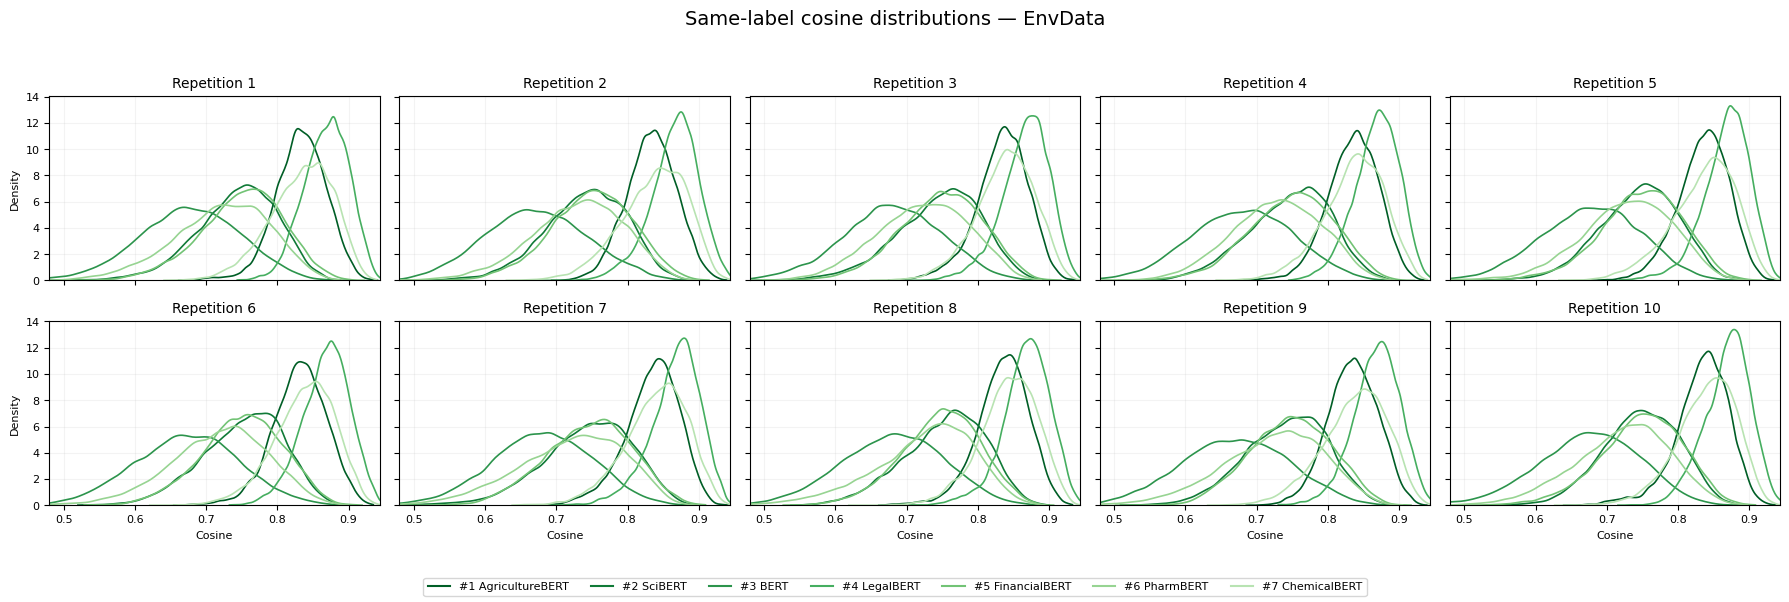

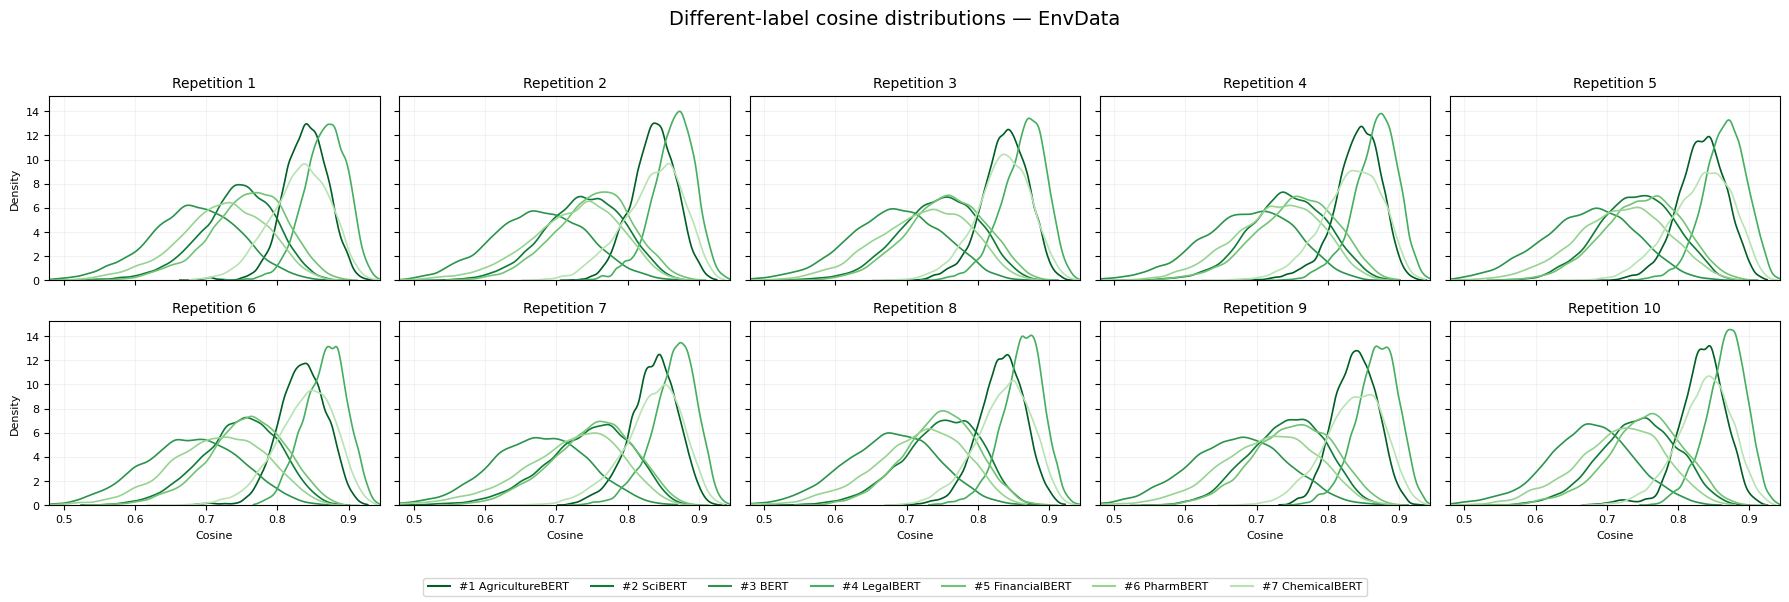

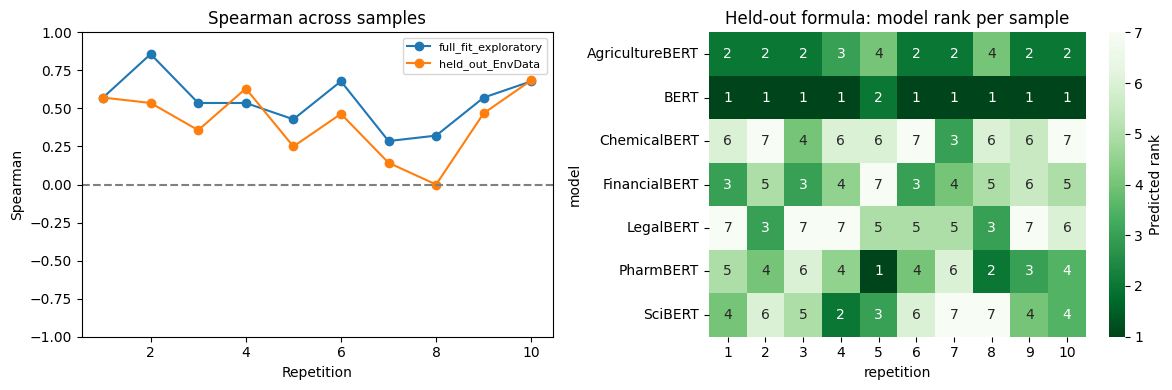

COMPLETED: 10 repetitions, 70 model runs. Results: /home/amyliu/Desktop/GR/EnvData/results/uncertainty10_gpu_20261025_163632


In [27]:
from matplotlib.lines import Line2D
name_to_checkpoint = {v:k for k,v in MODEL_NAMES.items()}
real_ranks = dict(zip(order, actual))
colors = {name:plt.cm.Greens(np.interp(real_ranks[name],[1,7],[.92,.30])) for name in order}
all_scores = np.concatenate([np.asarray(result[key],dtype=float)
    for result in results["full_results"].values() for key in ["same_scores","diff_scores_original"]])
xmin = max(-1, np.quantile(all_scores,.001)-.01)
xmax = min(1, np.quantile(all_scores,.999)+.01)
for key, title, filename in [
    ("same_scores","Same-label cosine distributions","same_label_all_10_repetitions.png"),
    ("diff_scores_original","Different-label cosine distributions","different_label_all_10_repetitions.png")]:
    fig, axes = plt.subplots(2,5,figsize=(18,6),sharex=True,sharey=True)
    for rep, ax in enumerate(axes.flat,start=1):
        for name in sorted(order,key=real_ranks.get):
            values = np.asarray(results["full_results"][(rep,name_to_checkpoint[name])][key],dtype=float)
            sns.kdeplot(x=values,ax=ax,color=colors[name],bw_adjust=.8,clip=(-1,1),cut=0,linewidth=1.2)
        ax.set_title(f"Repetition {rep}",fontsize=10)
        ax.set_xlim(xmin,xmax);ax.set_xlabel("Cosine",fontsize=8);ax.set_ylabel("Density",fontsize=8)
        ax.tick_params(labelsize=8);ax.grid(alpha=.15)
    fig.suptitle(title+" — EnvData",fontsize=14)
    fig.legend(handles=[Line2D([0],[0],color=colors[name],label=f"#{int(real_ranks[name])} {name}")
        for name in sorted(order,key=real_ranks.get)],loc="lower center",ncol=7,fontsize=8)
    fig.tight_layout(rect=[0,.07,1,.95])
    fig.savefig(OUTPUT_DIR / filename,dpi=180,bbox_inches="tight")
    plt.show();plt.close(fig)
fig, axes=plt.subplots(1,2,figsize=(12,4))
for procedure,g in round_df.groupby("procedure"):
    axes[0].plot(g.repetition,g.spearman,marker="o",label=procedure)
axes[0].axhline(0,color="gray",linestyle="--");axes[0].set_ylim(-1,1)
axes[0].set(xlabel="Repetition",ylabel="Spearman",title="Spearman across samples");axes[0].legend(fontsize=8)
rank_matrix=score_df.query('procedure == "held_out_EnvData"').pivot(index="model",columns="repetition",values="predicted_rank")
sns.heatmap(rank_matrix,annot=True,fmt=".0f",cmap="Greens_r",vmin=1,vmax=7,ax=axes[1],cbar_kws={"label":"Predicted rank"})
axes[1].set_title("Held-out formula: model rank per sample")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "combination_stability.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
print("COMPLETED: 10 repetitions, 70 model runs. Results:", OUTPUT_DIR.resolve())
